# Alloy Production & Distribution: LP/MILP model

OR1 course project, Phase 2 (Sharif University of Technology, Fall 2024). The model from Phase 1 is built in **Pyomo** and solved with **GLPK**. Section headings below are in Persian; each section answers one part of the assignment:

| Part | Topic |
|---|---|
| ج (c) | Optimal solution with and without the 5% bulk discount |
| د (d) | Maximum metal-to-alloy conversion cost for in-house production to stay worthwhile |
| ه (e) | Maximum initial contract cost for buying from factories 1 and 2 |
| و (f) | Ranges of the alloy purchase prices |
| ز (g) | Effect of one objective coefficient and one right-hand side on profit |
| ح (h) | ±10% uncertainty in transport costs (tables 4 and 5) |
| ط (i) | Adding Abadan as a new sales city |

**Optimal profit:** 1,285,190 without discount · 1,477,640 with discount


<h1 dir='rtl'>پروژه‌ی تحقیق در عملیات (فاز دوم)
</h1>

<h6 dir='rtl'>امیرحسین شهرابی</h6> <h6 dir='rtl'>محمدعرفان کلماتیان</h6> <h6 dir='rtl'>نیما باقرنژاد</h6><h6 dir='rtl'>علیرضا فرجی</h6>

<h2 dir='rtl'>تعریف و حل مدل </h2>

In [18]:
from pyomo.environ import ConcreteModel, Set, Var, Param, NonNegativeReals, NonNegativeIntegers, Binary, Objective, maximize, Constraint, ConstraintList
from pyomo.opt import SolverFactory

model = ConcreteModel()

model.j = Set(initialize=['A', 'B']) 
model.k = Set(initialize=['Tehran', 'Esfahan']) 
model.e = Set(initialize=['Mashhad', 'Kerman', 'Ahvaz', 'Tabriz'])  
model.t = Set(initialize=['Zinc', 'Iron', 'Copper', 'Aluminum', 'Others']) 
model.i = Set(initialize=['Ore1', 'Ore2', 'Ore3'])  
model.w = Set(initialize=['Factory1', 'Factory2'])  
model.lambda_set = Set(initialize=['Factory0', 'Factory1', 'Factory2']) 

model.m = Var(model.j, model.k, model.e, within=NonNegativeReals)

model.d = Var(model.j, model.k, model.e, within=NonNegativeIntegers)

model.x = Var(model.t, model.i, within=NonNegativeReals)

model.l = Var(model.t, model.j, within=NonNegativeReals)

model.y = Var(model.j, within=NonNegativeReals)

model.q = Var(model.j, model.w, within=NonNegativeReals)

model.f = Var(model.w, within=Binary)

model.h = Var(model.j, model.lambda_set, model.k, within=NonNegativeIntegers)

model.n = Var(model.j, model.lambda_set, model.k, within=NonNegativeReals)

model.delta = Var(model.w, within=Binary)

model.discounted_cost_Factory1 = Var(within=NonNegativeReals)
model.discounted_cost_Factory2 = Var(within=NonNegativeReals)

model.discounted_cost_Factory1_linear = Var(within=NonNegativeReals)
model.discounted_cost_Factory2_linear = Var(within=NonNegativeReals)

model.z1_A = Var(within=NonNegativeReals)  
model.z1_B = Var(within=NonNegativeReals)  
model.z2_A = Var(within=NonNegativeReals)  
model.z2_B = Var(within=NonNegativeReals)  

sales_prices = {
    'Mashhad': {'A': 520, 'B': 700},
    'Kerman': {'A': 540, 'B': 690},
    'Ahvaz': {'A': 490, 'B': 730},
    'Tabriz': {'A': 500, 'B': 710},
}

model.price_A = Param(model.e, initialize={e: sales_prices[e]['A'] for e in sales_prices}, mutable=True)

model.price_B = Param(model.e, initialize={e: sales_prices[e]['B'] for e in sales_prices}, mutable=True)

ore_composition = {
    'Ore1': {'Zinc': 25, 'Iron': 5, 'Copper': 30, 'Aluminum': 35, 'Others': 5},
    'Ore2': {'Zinc': 15, 'Iron': 20, 'Copper': 25, 'Aluminum': 30, 'Others': 10},
    'Ore3': {'Zinc': 5, 'Iron': 5, 'Copper': 65, 'Aluminum': 25, 'Others': 0},
}

model.ore_composition = Param(model.i, model.t, initialize={(i, t): ore_composition[i][t] for i in ore_composition for t in ore_composition[i]})

contract_costs = {
    'Factory1': {'initial_cost': 120, 'price_A': 375, 'price_B': 520, 'min_order': 2000, 'max_order': 5000},
    'Factory2': {'initial_cost': 90, 'price_A': 390, 'price_B': 540, 'min_order': 2500, 'max_order': 6000},
}

model.initial_cost = Param(model.w, initialize={w: contract_costs[w]['initial_cost'] for w in contract_costs}, mutable=True)

model.price_purchase_A = Param(model.w, initialize={w: contract_costs[w]['price_A'] for w in contract_costs}, mutable=True)

model.price_purchase_B = Param(model.w, initialize={w: contract_costs[w]['price_B'] for w in contract_costs}, mutable=True)

model.min_order = Param(model.w, initialize={w: contract_costs[w]['min_order'] for w in contract_costs})

model.max_order = Param(model.w, initialize={w: contract_costs[w]['max_order'] for w in contract_costs})

model.conversion_to_alloy= Param(initialize=250, mutable=True)

transport_costs = {
    'Factory0': {'Tehran': 200, 'Esfahan': 230},
    'Factory1': {'Tehran': 180, 'Esfahan': 210},
    'Factory2': {'Tehran': 240, 'Esfahan': 220},
}
model.transport_cost = Param(model.lambda_set, model.k, initialize={(lam, k): transport_costs[lam][k] for lam in transport_costs for k in transport_costs[lam]}, mutable=True)

delivery_cost = {
    'Tehran': {'Mashhad': 110, 'Kerman': 85, 'Ahvaz':120, 'Tabriz':100 },
    'Esfahan': {'Mashhad': 100, 'Kerman': 100, 'Ahvaz':110, 'Tabriz':90},
}

model.delivery_cost = Param(model.k, model.e, initialize={(k,e): delivery_cost[k][e] for k in delivery_cost for e in delivery_cost[k]}, mutable=True)

extraction_costs = {
    'Ore1': 45,
    'Ore2': 65,
    'Ore3': 70,
}

model.extraction_cost = Param(model.i, initialize={i: extraction_costs[i] for i in extraction_costs})

min_containers = {
    ('Factory0', 'Tehran'): 5, ('Factory0', 'Esfahan'): 5,
    ('Factory1', 'Tehran'): 10, ('Factory1', 'Esfahan'): 10,
    ('Factory2', 'Tehran'): 5, ('Factory2', 'Esfahan'): 5,
}

max_containers = {
    ('Factory0', 'Tehran'): 20, ('Factory0', 'Esfahan'): 20,
    ('Factory1', 'Tehran'): 30, ('Factory1', 'Esfahan'): 30,
    ('Factory2', 'Tehran'): 25, ('Factory2', 'Esfahan'): 15,
}

model.min_containers = Param(model.lambda_set, model.k, initialize=min_containers)
model.max_containers = Param(model.lambda_set, model.k, initialize=max_containers)

min_delivery = {
    ('Tehran', 'Mashhad'): 3, ('Tehran', 'Kerman'): 6, ('Tehran', 'Ahvaz'): 10, ('Tehran', 'Tabriz'): 5,
    ('Esfahan', 'Mashhad'): 4, ('Esfahan', 'Kerman'): 5, ('Esfahan', 'Ahvaz'): 5, ('Esfahan', 'Tabriz'): 10,
}

max_delivery = {
    ('Tehran', 'Mashhad'): 7, ('Tehran', 'Kerman'): 12, ('Tehran', 'Ahvaz'): 18, ('Tehran', 'Tabriz'): 15,
    ('Esfahan', 'Mashhad'): 6, ('Esfahan', 'Kerman'): 14, ('Esfahan', 'Ahvaz'): 20, ('Esfahan', 'Tabriz'): 20,
}

model.min_delivery = Param(model.k, model.e, initialize=min_delivery)
model.max_delivery = Param(model.k, model.e, initialize=max_delivery)

demand = {
    ('A', 'Mashhad'): 600, ('A', 'Kerman'): 800, ('A', 'Ahvaz'): 1500, ('A', 'Tabriz'): 1400,
    ('B', 'Mashhad'): 400, ('B', 'Kerman'): 1200, ('B', 'Ahvaz'): 1500, ('B', 'Tabriz'): 1100,
}

model.demand = Param(model.j, model.e, initialize=demand, mutable=True)

<h2 dir='rtl'>تابع هدف بدون تخفیف
</h2>

In [19]:
def corrected_objective_function(model):
    return (
        sum(
            model.price_A[e] * sum(model.m['A', k, e] for k in model.k)
            for e in model.e
        ) +
        sum(
            model.price_B[e] * sum(model.m['B', k, e] for k in model.k)
            for e in model.e
        ) -
        sum(
            model.extraction_cost[i] * sum(model.x[t, i] for t in model.t)
            for i in model.i
        ) -
        model.conversion_to_alloy * sum(model.y[j] for j in model.j) -
        sum(model.initial_cost[w]*model.f[w] for w in model.w)-
        sum(model.price_purchase_A[w] * model.q['A', w] for w in model.w) -
        sum(model.price_purchase_B[w] * model.q['B', w] for w in model.w) -
        sum(
            model.transport_cost[lam, k] * sum(model.h[j, lam, k] for j in model.j)
            for lam in model.lambda_set for k in model.k
        ) -
        sum(
            model.delivery_cost[k, e] * model.d[j, k, e]
            for j in model.j for k in model.k for e in model.e
        )
    )

<h2 dir='rtl'>تابع هدف با تخفیف</h2>

In [20]:
def objective_with_discount(model):
    return (
        sum(
            model.price_A[e] * sum(model.m['A', k, e] for k in model.k)
            for e in model.e
        ) +
        sum(
            model.price_B[e] * sum(model.m['B', k, e] for k in model.k)
            for e in model.e
        ) -
        sum(
            model.extraction_cost[i] * sum(model.x[t, i] for t in model.t)
            for i in model.i
        ) -
        model.conversion_to_alloy * sum(model.y[j] for j in model.j) -
        sum(model.initial_cost[w]*model.f[w] for w in model.w)-
        (model.discounted_cost_Factory1_linear + model.discounted_cost_Factory2_linear) -
        sum(
            model.transport_cost[lam, k] * sum(model.h[j, lam, k] for j in model.j)
            for lam in model.lambda_set for k in model.k
        ) -
        sum(
            model.delivery_cost[k, e] * model.d[j, k, e]
            for j in model.j for k in model.k for e in model.e
        )
    )

model.objective_no_discount = Objective(rule=corrected_objective_function, sense=maximize)
model.objective_with_discount = Objective(rule=objective_with_discount, sense=maximize)  

model.discount_constraints = ConstraintList()

model.discount_constraints.add(model.z1_A <= model.q['A', 'Factory1'])
model.discount_constraints.add(model.z1_A <= model.delta['Factory1'] * model.max_order['Factory1'])
model.discount_constraints.add(model.z1_A >= model.q['A', 'Factory1'] - (1 - model.delta['Factory1']) * model.max_order['Factory1'])
model.discount_constraints.add(model.z1_A >= 0)

model.discount_constraints.add(model.z1_B <= model.q['B', 'Factory1'])
model.discount_constraints.add(model.z1_B <= model.delta['Factory1'] * model.max_order['Factory1'])
model.discount_constraints.add(model.z1_B >= model.q['B', 'Factory1'] - (1 - model.delta['Factory1']) * model.max_order['Factory1'])
model.discount_constraints.add(model.z1_B >= 0)

model.discount_constraints.add(
    model.discounted_cost_Factory1_linear ==
    model.price_purchase_A['Factory1'] * model.q['A', 'Factory1'] +
    model.price_purchase_B['Factory1'] * model.q['B', 'Factory1'] -
    0.05 * (model.price_purchase_A['Factory1'] * model.z1_A +
            model.price_purchase_B['Factory1'] * model.z1_B)
)


model.discount_constraints.add(model.z2_A <= model.q['A', 'Factory2'])
model.discount_constraints.add(model.z2_A <= model.delta['Factory2'] * model.max_order['Factory2'])
model.discount_constraints.add(model.z2_A >= model.q['A', 'Factory2'] - (1 - model.delta['Factory2']) * model.max_order['Factory2'])
model.discount_constraints.add(model.z2_A >= 0)

model.discount_constraints.add(model.z2_B <= model.q['B', 'Factory2'])
model.discount_constraints.add(model.z2_B <= model.delta['Factory2'] * model.max_order['Factory2'])
model.discount_constraints.add(model.z2_B >= model.q['B', 'Factory2'] - (1 - model.delta['Factory2']) * model.max_order['Factory2'])
model.discount_constraints.add(model.z2_B >= 0)

model.discount_constraints.add(
    model.discounted_cost_Factory2_linear ==
    model.price_purchase_A['Factory2'] * model.q['A', 'Factory2'] +
    model.price_purchase_B['Factory2'] * model.q['B', 'Factory2'] -
    0.05 * (model.price_purchase_A['Factory2'] * model.z2_A +
            model.price_purchase_B['Factory2'] * model.z2_B)
)

<h2 dir='rtl'>تعریف محدودیت‌های مدل</h2>

In [21]:
model.balance_constraints = ConstraintList()
for i in model.i:
    for t in model.t:
        if i == 'Ore1':
            coefficients = {'Zinc': 0.25, 'Iron': 0.05, 'Copper': 0.3, 'Aluminum': 0.35, 'Others': 0.05}
        elif i == 'Ore2':
            coefficients = {'Zinc': 0.15, 'Iron': 0.2, 'Copper': 0.25, 'Aluminum': 0.3, 'Others': 0.1}
        else:  # i == 'Ore3'
            coefficients = {'Zinc': 0.05, 'Iron': 0.05, 'Copper': 0.65, 'Aluminum': 0.25, 'Others': 0.0}

        model.balance_constraints.add(model.x[t, i] == coefficients[t] * sum(model.x[t_prime, i] for t_prime in model.t))


model.alloy_constraints = ConstraintList()

model.alloy_constraints.add(model.l['Zinc', 'A'] <= 0.8 * model.y['A'])
model.alloy_constraints.add(model.l['Iron', 'A'] <= 0.25 * model.y['A'])
model.alloy_constraints.add(model.l['Aluminum', 'A'] >= 0.55 * model.y['A'])
model.alloy_constraints.add(sum(model.l[t, 'A'] for t in model.t) == model.y['A'])

model.alloy_constraints.add(model.l['Iron', 'B'] >= 0.45 * model.y['B'])
model.alloy_constraints.add(model.l['Iron', 'B'] <= 0.7 * model.y['B'])
model.alloy_constraints.add(model.l['Copper', 'B'] >= 0.35 * model.y['B'])
model.alloy_constraints.add(model.l['Aluminum', 'B'] <= 0.7 * model.y['B'])
model.alloy_constraints.add(sum(model.l[t, 'B'] for t in model.t) == model.y['B'])


for t in model.t:
    if t not in ['Zinc', 'Iron', 'Aluminum']: 
        model.alloy_constraints.add(model.l[t, 'A'] == 0)

for t in model.t:
    if t not in ['Iron', 'Copper', 'Aluminum']:  
        model.alloy_constraints.add(model.l[t, 'B'] == 0)


model.metal_balance_constraints = ConstraintList()
model.metal_balance_constraints.add(model.l['Zinc', 'A'] == sum(model.x['Zinc', i] for i in model.i))
model.metal_balance_constraints.add(model.l['Copper', 'B'] == sum(model.x['Copper', i] for i in model.i))
model.metal_balance_constraints.add(model.l['Aluminum', 'A'] + model.l['Aluminum', 'B'] == sum(model.x['Aluminum', i] for i in model.i))
model.metal_balance_constraints.add(model.l['Iron', 'A'] + model.l['Iron', 'B'] == sum(model.x['Iron', i] for i in model.i))

model.factory_purchase_constraints = ConstraintList()
for w in model.w:
    model.factory_purchase_constraints.add(sum(model.q[j, w] for j in model.j) <= model.max_order[w] * model.f[w])
    model.factory_purchase_constraints.add(sum(model.q[j, w] for j in model.j) >= model.min_order[w] * model.f[w])


model.container_constraints = ConstraintList()
for lam in model.lambda_set:
    for k in model.k:
        model.container_constraints.add(sum(model.h[j, lam, k] for j in model.j) <= model.max_containers[lam, k])
        model.container_constraints.add(sum(model.h[j, lam, k] for j in model.j) >= model.min_containers[lam, k])


model.tonnage_balance_constraints = ConstraintList()
for j in model.j:
    for lam in model.lambda_set:
        for k in model.k:
            model.tonnage_balance_constraints.add(100 * model.h[j, lam, k] >= model.n[j, lam, k])


model.storage_balance_constraints = ConstraintList()

for j in model.j:
    model.storage_balance_constraints.add(
        model.y[j] == sum(model.n[j, 'Factory0', k] for k in model.k)
    )


for j in model.j:
    for k in model.k:
        model.storage_balance_constraints.add(
            sum(model.n[j, lam, k] for lam in model.lambda_set) == sum(model.m[j, k, e] for e in model.e)
        )



model.warehouse_constraints = ConstraintList()

model.warehouse_constraints.add(20 <= sum(sum(model.h[j, lam, 'Tehran'] for lam in model.lambda_set) for j in model.j))
model.warehouse_constraints.add(sum(sum(model.h[j, lam, 'Tehran'] for lam in model.lambda_set) for j in model.j) <= 65)

model.warehouse_constraints.add(30 <= sum(sum(model.h[j, lam, 'Esfahan'] for lam in model.lambda_set) for j in model.j))
model.warehouse_constraints.add(sum(sum(model.h[j, lam, 'Esfahan'] for lam in model.lambda_set) for j in model.j) <= 70)

model.delivery_constraints = ConstraintList()
for k in model.k:
    for e in model.e:
        model.delivery_constraints.add(sum(model.d[j, k, e] for j in model.j) >= model.min_delivery[k, e])
        model.delivery_constraints.add(sum(model.d[j, k, e] for j in model.j) <= model.max_delivery[k, e])

model.capacity_constraints = ConstraintList()
for j in model.j:
    for k in model.k:
        for e in model.e:
          model.capacity_constraints.add(100 * model.d[j, k, e] >= model.m[j, k, e])


model.demand_constraints = ConstraintList()
for j in model.j:
    for e in model.e:
        model.demand_constraints.add(sum(model.m[j, k, e] for k in model.k) <= model.demand[j, e])

model.factory_to_warehouse_balance = ConstraintList()
for w in model.w:
    model.factory_to_warehouse_balance.add(
        model.q['A', w] == sum(model.n['A', w, k] for k in model.k)
    )
    model.factory_to_warehouse_balance.add(
        model.q['B', w] == sum(model.n['B', w, k] for k in model.k)
    )

<h3 dir='rtl'>چک کردن اطلاعات مدل</h2>

In [22]:
model.pprint()

<h2 dir='rtl'>پاسخ بهینه بند ج بدون تخفیف<h2>

In [23]:
model.objective_no_discount.activate()
model.objective_with_discount.deactivate()

solver = SolverFactory('glpk')
solver.solve(model)  # pass tee=True to see the full GLPK log

print("\n*** Solution without Discount ***")
print("Objective Value (No Discount):", model.objective_no_discount())
for v in model.component_objects(Var, active=True):
    varobject = getattr(model, str(v))
    for index in varobject:
        print(f"{v}[{index}] = {varobject[index].value}")


*** Solution without Discount ***
Objective Value (No Discount): 1285190.0000000005
m[('A', 'Tehran', 'Mashhad')] = 600.0
m[('A', 'Tehran', 'Kerman')] = 800.0
m[('A', 'Tehran', 'Ahvaz')] = 1100.0
m[('A', 'Tehran', 'Tabriz')] = 300.0
m[('A', 'Esfahan', 'Mashhad')] = 0.0
m[('A', 'Esfahan', 'Kerman')] = -2.27373675443232e-13
m[('A', 'Esfahan', 'Ahvaz')] = 400.0
m[('A', 'Esfahan', 'Tabriz')] = 1100.0
m[('B', 'Tehran', 'Mashhad')] = 0.0
m[('B', 'Tehran', 'Kerman')] = 400.0
m[('B', 'Tehran', 'Ahvaz')] = 700.000000000001
m[('B', 'Tehran', 'Tabriz')] = 1100.0
m[('B', 'Esfahan', 'Mashhad')] = 400.0
m[('B', 'Esfahan', 'Kerman')] = 800.0
m[('B', 'Esfahan', 'Ahvaz')] = 800.0
m[('B', 'Esfahan', 'Tabriz')] = 0.0
d[('A', 'Tehran', 'Mashhad')] = 6.0
d[('A', 'Tehran', 'Kerman')] = 8.0
d[('A', 'Tehran', 'Ahvaz')] = 11.0
d[('A', 'Tehran', 'Tabriz')] = 3.0
d[('A', 'Esfahan', 'Mashhad')] = 0.0
d[('A', 'Esfahan', 'Kerman')] = 0.0
d[('A', 'Esfahan', 'Ahvaz')] = 4.0
d[('A', 'Esfahan', 'Tabriz')] = 11.0
d[('B

<h2 dir='rtl'>پاسخ بهینه‌ی بند ج با تخفیف<h2>

In [24]:
model.objective_no_discount.deactivate()
model.objective_with_discount.activate()

solver.solve(model)  # pass tee=True to see the full GLPK log

print("\n*** Solution with Discount ***")
print("Objective Value (With Discount):", model.objective_with_discount())
for v in model.component_objects(Var, active=True):
    varobject = getattr(model, str(v))
    for index in varobject:
        print(f"{v}[{index}] = {varobject[index].value}")

del model.objective_with_discount

model.objective_no_discount.activate()


*** Solution with Discount ***
Objective Value (With Discount): 1477640.0
m[('A', 'Tehran', 'Mashhad')] = 200.0
m[('A', 'Tehran', 'Kerman')] = 800.0
m[('A', 'Tehran', 'Ahvaz')] = 1500.0
m[('A', 'Tehran', 'Tabriz')] = 300.0
m[('A', 'Esfahan', 'Mashhad')] = 400.0
m[('A', 'Esfahan', 'Kerman')] = 0.0
m[('A', 'Esfahan', 'Ahvaz')] = 0.0
m[('A', 'Esfahan', 'Tabriz')] = 1100.0
m[('B', 'Tehran', 'Mashhad')] = 400.0
m[('B', 'Tehran', 'Kerman')] = 400.0
m[('B', 'Tehran', 'Ahvaz')] = 300.0
m[('B', 'Tehran', 'Tabriz')] = 1100.0
m[('B', 'Esfahan', 'Mashhad')] = 0.0
m[('B', 'Esfahan', 'Kerman')] = 800.0
m[('B', 'Esfahan', 'Ahvaz')] = 1200.0
m[('B', 'Esfahan', 'Tabriz')] = 0.0
d[('A', 'Tehran', 'Mashhad')] = 2.0
d[('A', 'Tehran', 'Kerman')] = 8.0
d[('A', 'Tehran', 'Ahvaz')] = 15.0
d[('A', 'Tehran', 'Tabriz')] = 3.0
d[('A', 'Esfahan', 'Mashhad')] = 4.0
d[('A', 'Esfahan', 'Kerman')] = 0.0
d[('A', 'Esfahan', 'Ahvaz')] = 0.0
d[('A', 'Esfahan', 'Tabriz')] = 11.0
d[('B', 'Tehran', 'Mashhad')] = 4.0
d[('B',

<h2 dir='rtl'> بند د، تحلیل حساسیت نسبت به تغییر هزینه‌ی تبدیل فلز به آلیاژ</h2>

In [25]:
production_cost_values = range(00, 300, 10)  
results = []

for cost in production_cost_values:
    model.conversion_to_alloy.set_value(cost)
    solver.solve(model, tee=False)
    obj_value = model.objective_no_discount()
    y_values = {j: model.y[j].value for j in model.j}
    results.append((cost, obj_value, y_values))

print("Production Cost Sensitivity Analysis:")
print("Cost\tObjective Value\tY Values")
for cost, obj_value, y_values in results:
    y_str = ", ".join([f"{j}: {value:.2f}" for j, value in y_values.items()])
    print(f"{cost}\t{obj_value:.2f}\t{y_str}")

Production Cost Sensitivity Analysis:
Cost	Objective Value	Y Values
0	1285190.00	A: 0.00, B: 0.00
10	1285190.00	A: 0.00, B: 0.00
20	1285190.00	A: 0.00, B: 0.00
30	1285190.00	A: 0.00, B: 0.00
40	1285190.00	A: 0.00, B: 0.00
50	1285190.00	A: 0.00, B: 0.00
60	1285190.00	A: 0.00, B: 0.00
70	1285190.00	A: 0.00, B: 0.00
80	1285190.00	A: 0.00, B: 0.00
90	1285190.00	A: 0.00, B: 0.00
100	1285190.00	A: 0.00, B: 0.00
110	1285190.00	A: 0.00, B: 0.00
120	1285190.00	A: 0.00, B: 0.00
130	1285190.00	A: 0.00, B: 0.00
140	1285190.00	A: 0.00, B: 0.00
150	1285190.00	A: 0.00, B: 0.00
160	1285190.00	A: 0.00, B: 0.00
170	1285190.00	A: 0.00, B: 0.00
180	1285190.00	A: -0.00, B: 0.00
190	1285190.00	A: -0.00, B: 0.00
200	1285190.00	A: 0.00, B: 0.00
210	1285190.00	A: 0.00, B: 0.00
220	1285190.00	A: 0.00, B: 0.00
230	1285190.00	A: 0.00, B: 0.00
240	1285190.00	A: 0.00, B: 0.00
250	1285190.00	A: 0.00, B: 0.00
260	1285190.00	A: 0.00, B: 0.00
270	1285190.00	A: 0.00, B: 0.00
280	1285190.00	A: 0.00, B: 0.00
290	1285190.0

In [26]:
from pyomo.environ import value
def sensitivity_analysis_production_cost(model, increment, steps):
    base_cost = value(model.conversion_to_alloy)
    sensitivity_results = []  # To store the results

    for step in range(-steps, steps + 1):
        new_cost = base_cost + step * increment
        model.conversion_to_alloy = new_cost

        # Solve the model
        solver = SolverFactory('glpk')  # Replace 'glpk' with your solver
        solver_results = solver.solve(model)

        # Check if production is feasible
        feasible = any(value(model.y[j]) > 0 for j in model.j)
        objective_value = value(model.objective_no_discount)

        sensitivity_results.append((new_cost, objective_value, feasible))

        if not feasible:
            break  # Stop if production becomes infeasible

    # Reset the cost to its original value
    model.conversion_to_alloy = base_cost
    return sensitivity_results

# Perform sensitivity analysis for production costs
print("\nSensitivity Analysis for Production Costs:")
sensitivity_results = sensitivity_analysis_production_cost(
    model, increment=10, steps=10
)
print(f"Results: {sensitivity_results}")


Sensitivity Analysis for Production Costs:


Results: [(190, 1285189.9999999998, True), (200, 1285190.0, False)]


<h2 dir='rtl'> بند ه تحلیل حساسیت نسبت به هزینه قرارداد اولیه</h2>

In [27]:
from pyomo.environ import value

def sensitivity_analysis_initial_cost(model, factory, param_name, increment, steps):
    base_cost = value(getattr(model,param_name)[factory])
    sensitivity_results = []  # To store the results
    

    for step in range(-steps, steps + 1):
        new_cost = base_cost + step * increment
        getattr(model, param_name)[factory] = new_cost

        # Solve the model
        solver = SolverFactory('glpk')  # Replace 'glpk' with your solver
        solver_results = solver.solve(model)

        # Check if purchasing from the factory is feasible
        feasible = all(value(model.f[factory]) == 1 for factory in model.w)
        objective_value = value(model.objective_no_discount)

        sensitivity_results.append((new_cost, objective_value, feasible))

        if not feasible:
            break  # Stop if purchasing becomes infeasible

    # Reset the cost to its original value
    getattr(model,param_name)[factory] = base_cost
    return sensitivity_results

# Perform sensitivity analysis for initial costs
factories = ['Factory1', 'Factory2']
params='initial_cost'

for factory in factories:
    print(f"\nSensitivity Analysis for initial_cost of {factory}:")
    sensitivity_results = sensitivity_analysis_initial_cost(
        model, factory, params,  increment=10, steps=10
    )
    print(f"Results: {sensitivity_results}")


Sensitivity Analysis for initial_cost of Factory1:
Results: [(20, 1285289.9999999986, True), (30, 1285279.9999999986, True), (40, 1285269.9999999986, True), (50, 1285259.9999999986, True), (60, 1285249.9999999986, True), (70, 1285240.0000000007, True), (80, 1285229.9999999986, True), (90, 1285219.9999999986, True), (100, 1285210.0000000007, True), (110, 1285199.9999999986, True), (120, 1285190.0000000005, True), (130, 1285180.0000000007, True), (140, 1285169.9999999986, True), (150, 1285159.9999999986, True), (160, 1285149.9999999986, True), (170, 1285140.0000000007, True), (180, 1285129.9999999986, True), (190, 1285119.9999999986, True), (200, 1285110.0000000007, True), (210, 1285099.9999999986, True), (220, 1285090.0000000005, True)]

Sensitivity Analysis for initial_cost of Factory2:
Results: [(-10, 1285290.0000000005, True), (0, 1285280.0000000005, True), (10, 1285270.0000000005, True), (20, 1285260.0000000005, True), (30, 1285250.0000000005, True), (40, 1285240.0000000005, True),

<h2 dir='rtl'> بند و تحلیل حساسیت نسبت به تغییر هزینه‌ی خرید آلیاژ</h2>

In [28]:
from pyomo.environ import value

def sensitivity_analysis_purchase_costs(model, param_name, factory, increment, steps):
    base_cost = value(getattr(model, param_name)[factory])
    sensitivity_results = []  
    original_solution = [(v.name, tuple(v.index_set())) for v in model.component_objects(Var, active=True)]

    for step in range(-steps, steps + 1):
        new_cost = base_cost + step * increment
        getattr(model, param_name)[factory] = new_cost

        solver_results = solver.solve(model)

        current_solution = [(v.name, tuple(v.index_set())) for v in model.component_objects(Var, active=True)]

        basis_unchanged = current_solution == original_solution
        objective_value = value(model.objective_no_discount)
        sensitivity_results.append((new_cost, objective_value, basis_unchanged))

        if not basis_unchanged:
            break  

    
    getattr(model, param_name)[factory] = base_cost
    return sensitivity_results


factories = ['Factory1', 'Factory2']
params = ['price_purchase_A', 'price_purchase_B']

for factory in factories:
    for param_name in params:
        print(f"\nSensitivity Analysis for {param_name} from {factory}:")
        sensitivity_results = sensitivity_analysis_purchase_costs(
            model, param_name, factory, increment=10, steps=10
        )
        print(f"Results: {sensitivity_results}")


Sensitivity Analysis for price_purchase_A from Factory1:
Results: [(275, 1697690.0, True), (285, 1654690.0, True), (295, 1611690.0, True), (305, 1568690.0, True), (315, 1525689.9999999995, True), (325, 1482690.0, True), (335, 1439690.0, True), (345, 1396690.0, True), (355, 1353690.0, True), (365, 1310690.0, True), (375, 1285190.0000000005, True), (385, 1277189.9999999998, True), (395, 1271410.0, True), (405, 1268410.0, True), (415, 1265410.0, True), (425, 1262410.0, True), (435, 1259410.0, True), (445, 1256410.0, True), (455, 1253410.0, True), (465, 1250410.0, True), (475, 1247410.0, True)]

Sensitivity Analysis for price_purchase_B from Factory1:
Results: [(420, 1705190.0, True), (430, 1663190.0, True), (440, 1621190.0, True), (450, 1579190.0, True), (460, 1537190.0000000002, True), (470, 1495189.9999999998, True), (480, 1453189.9999999998, True), (490, 1411189.9999999998, True), (500, 1369189.9999999998, True), (510, 1327189.9999999967, True), (520, 1285190.0000000005, True), (530, 

<h2 dir='rtl'>بند ز تحلیل حساسیت نسبت به یک ضریب تابع هدف و یک مقدار سمت راست</h2>


Sensitivity Analysis on Objective Coefficient (price_A):

Sensitivity Analysis on RHS (demand):


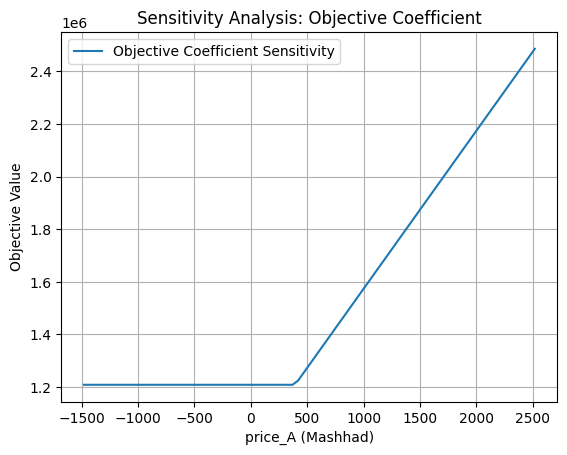

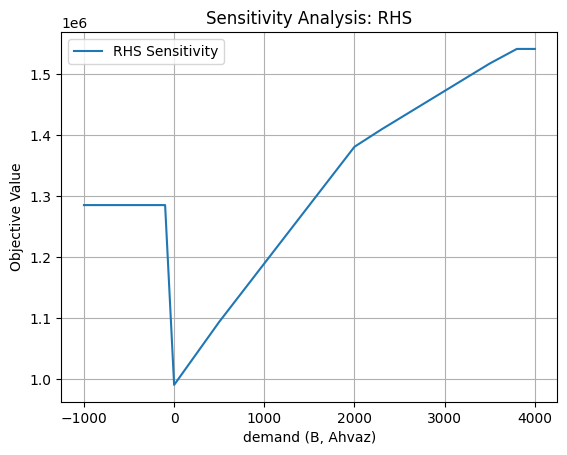

In [29]:
import matplotlib.pyplot as plt
def sensitivity_analysis_objective_coefficient(model, param_name, increment, steps, city):
    base_value = value(getattr(model, param_name)[city])
    results = []

    for step in range(-steps, steps + 1):
        new_value = base_value + step * increment
        getattr(model, param_name)[city] = new_value

        solver.solve(model)

        objective_value = value(model.objective_no_discount)
        results.append((new_value, objective_value))

    getattr(model, param_name)[city] = base_value
    return results


def sensitivity_analysis_rhs(model, param_name, increment, steps, alloy, city):
    base_value = value(getattr(model, param_name)[alloy, city])
    results = []

    for step in range(-steps, steps + 1):
        new_value = base_value + step * increment
        getattr(model, param_name)[alloy, city] = new_value

        solver.solve(model)

        objective_value = value(model.objective_no_discount)
        results.append((new_value, objective_value))

    getattr(model, param_name)[alloy, city] = base_value
    return results

print("\nSensitivity Analysis on Objective Coefficient (price_A):")
objective_results = sensitivity_analysis_objective_coefficient(
    model, param_name='price_A', increment=50, steps=40, city='Mashhad'
)

print("\nSensitivity Analysis on RHS (demand):")
rhs_results = sensitivity_analysis_rhs(
    model, param_name='demand', increment=100, steps=25, alloy='B', city='Ahvaz'
)

plt.figure()
objective_x, objective_y = zip(*objective_results)
plt.plot(objective_x, objective_y, label='Objective Coefficient Sensitivity')
plt.xlabel('price_A (Mashhad)')
plt.ylabel('Objective Value')
plt.title('Sensitivity Analysis: Objective Coefficient')
plt.legend()
plt.grid()
plt.show()

plt.figure()
rhs_x, rhs_y = zip(*rhs_results)
plt.plot(rhs_x, rhs_y, label='RHS Sensitivity')
plt.xlabel('demand (B, Ahvaz)')
plt.ylabel('Objective Value')
plt.title('Sensitivity Analysis: RHS')
plt.legend()
plt.grid()
plt.show()

<h2 dir='rtl'>بند ح تحلیل حساسیت نسبت به تغییر هزینه‌های حمل‌ونقل (جداول 4 و 5)</h2>


Sensitivity Analysis for delivery_cost (Tehran to Mashhad):

Sensitivity Analysis for transport_cost (Factory1 to Tehran):


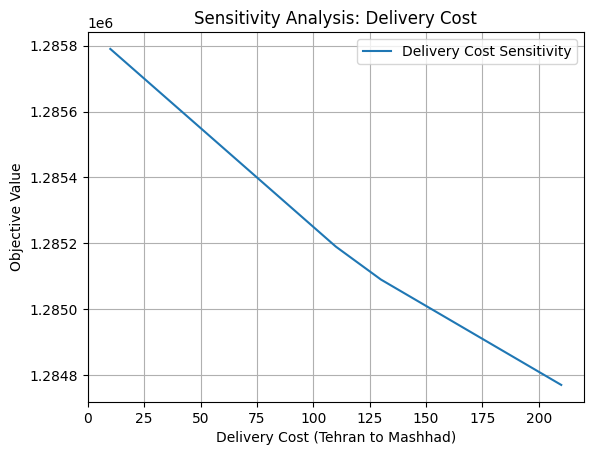

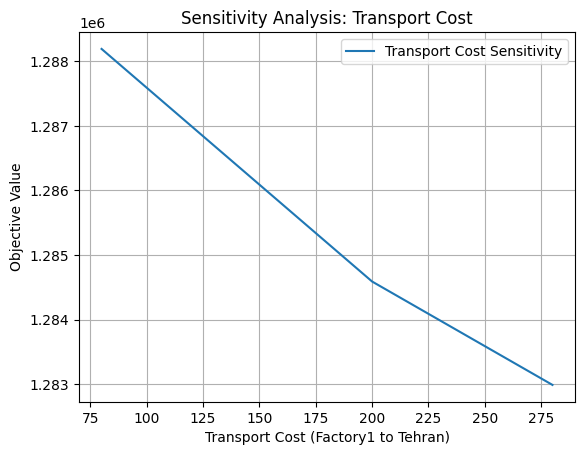

In [30]:
def sensitivity_analysis_delivery_cost(model, increment, steps, origin, destination):
    base_value = value(model.delivery_cost[origin, destination])
    results = []

    for step in range(-steps, steps + 1):
        new_value = base_value + step * increment
        model.delivery_cost[origin, destination] = new_value

        solver.solve(model)

        objective_value = value(model.objective_no_discount)
        results.append((new_value, objective_value))

    model.delivery_cost[origin, destination] = base_value
    return results

def sensitivity_analysis_transport_cost(model, increment, steps, factory, warehouse):
    base_value = value(model.transport_cost[factory, warehouse])
    results = []

    for step in range(-steps, steps + 1):
        new_value = base_value + step * increment
        model.transport_cost[factory, warehouse] = new_value

        solver.solve(model)

        objective_value = value(model.objective_no_discount)
        results.append((new_value, objective_value))

    model.transport_cost[factory, warehouse] = base_value
    return results

print("\nSensitivity Analysis for delivery_cost (Tehran to Mashhad):")
delivery_results = sensitivity_analysis_delivery_cost(
    model, increment=10, steps=10, origin='Tehran', destination='Mashhad'
)

print("\nSensitivity Analysis for transport_cost (Factory1 to Tehran):")
transport_results = sensitivity_analysis_transport_cost(
    model, increment=10, steps=10, factory='Factory1', warehouse='Tehran'
)

plt.figure()
delivery_x, delivery_y = zip(*delivery_results)
plt.plot(delivery_x, delivery_y, label='Delivery Cost Sensitivity')
plt.xlabel('Delivery Cost (Tehran to Mashhad)')
plt.ylabel('Objective Value')
plt.title('Sensitivity Analysis: Delivery Cost')
plt.legend()
plt.grid()
plt.show()

plt.figure()
transport_x, transport_y = zip(*transport_results)
plt.plot(transport_x, transport_y, label='Transport Cost Sensitivity')
plt.xlabel('Transport Cost (Factory1 to Tehran)')
plt.ylabel('Objective Value')
plt.title('Sensitivity Analysis: Transport Cost')
plt.legend()
plt.grid()
plt.show()

<h2 dir='rtl'>بخش ط تحلیل حساسیت نسبت به اضافه کردن شهر آبادان به مقاصد فروش و بررسی حداقل قیمت برای توجیه‌پذیری</h2>

In [31]:
model.e.add('Abadan')

model.delivery_cost['Tehran', 'Abadan'] = model.delivery_cost['Tehran', 'Ahvaz']
model.delivery_cost['Esfahan', 'Abadan'] = model.delivery_cost['Esfahan', 'Ahvaz']

def find_min_price(model, alloy, city, increment=10):
    min_price = 0
    max_price = 10000  
    while max_price - min_price > 1:  
        mid_price = (min_price + max_price) / 2
        if alloy == 'A':
            model.price_A[city] = mid_price
        elif alloy == 'B':
            model.price_B[city] = mid_price

        solver.solve(model)

        if value(model.objective_no_discount) > 0:  
            max_price = mid_price
        else:  
            min_price = mid_price

    return max_price


min_price_A_abadan = find_min_price(model, 'A', 'Abadan')
min_price_B_abadan = find_min_price(model, 'B', 'Abadan')


print(f"Minimum price for alloy A at Abadan: {min_price_A_abadan}")
print(f"Minimum price for alloy B at Abadan: {min_price_B_abadan}")

Minimum price for alloy A at Abadan: 0.6103515625
Minimum price for alloy B at Abadan: 0.6103515625
